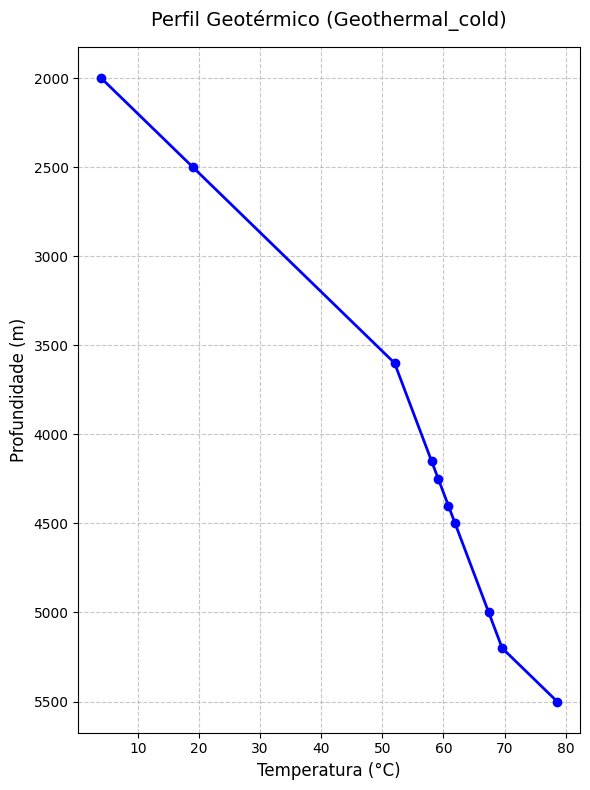

In [1]:
import matplotlib.pyplot as plt

# Estrutura de dados extraída do JSON da imagem
data = {
    "ThermalGradient": {
        "Geothermal_cold": [
            {"Depth": 2000.0, "Temperature": 4.0},
            {"Depth": 2500.0, "Temperature": 19.0},
            {"Depth": 3600.0, "Temperature": 52.0},
            {"Depth": 4150.0, "Temperature": 58.05},
            {"Depth": 4250.0, "Temperature": 59.15},
            {"Depth": 4400.0, "Temperature": 60.8},
            {"Depth": 4500.0, "Temperature": 61.9},
            {"Depth": 5000.0, "Temperature": 67.4},
            {"Depth": 5200.0, "Temperature": 69.6},
            {"Depth": 5500.0, "Temperature": 78.6}
        ]
    }
}

# Extraindo as listas de profundidade e temperatura
geothermal_data = data["ThermalGradient"]["Geothermal_cold"]
depths = [item["Depth"] for item in geothermal_data]
temperatures = [item["Temperature"] for item in geothermal_data]

# Configuração da figura e do plot
fig, ax = plt.subplots(figsize=(6, 8))

# Plotando Temperatura no eixo X e Profundidade no eixo Y
ax.plot(temperatures, depths, marker='o', linestyle='-', color='b', linewidth=2)

# Invertendo o eixo Y para refletir a profundidade real do poço (0 no topo)
ax.invert_yaxis()

# Formatação do gráfico
ax.set_title("Perfil Geotérmico (Geothermal_cold)", fontsize=14, pad=15)
ax.set_xlabel("Temperatura (°C)", fontsize=12)
ax.set_ylabel("Profundidade (m)", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)

# Ajuste de layout e exibição
plt.tight_layout()
plt.show()

In [13]:
%%writefile extract_pq_jupyter.py
from odbAccess import openOdb
from abaqusConstants import INTEGRATION_POINT
import sys

def ExportRockStressesAllFrames(odb_path, output_file):
    try:
        odb = openOdb(path=odb_path)
    except Exception as e:
        print("Erro ao abrir o ODB: {}".format(e))
        return

    a = odb.rootAssembly
    set_name = 'FASEI_OPEN_WELL' 
    
    if set_name not in a.elementSets.keys():
        print("Erro: O Element Set '{}' nao foi encontrado.".format(set_name))
        odb.close()
        return
        
    target_set = a.elementSets[set_name]

    with open(output_file, 'w') as f:
        f.write("Time_s,Element_Label,p_PRESS_MPa,q_MISES_MPa\n")
        
        for step in odb.steps.values():
            for frame in step.frames:
                time = frame.frameValue
                
                # Extrai tensoes nos pontos de integracao
                press_field = frame.fieldOutputs['PRESSONLY'].getSubset(region=target_set, position=INTEGRATION_POINT)
                mises_field = frame.fieldOutputs['S'].getSubset(region=target_set, position=INTEGRATION_POINT)
                
                for press_val, s_val in zip(press_field.values, mises_field.values):
                    e_label = press_val.elementLabel
                    p_val = press_val.data
                    q_val = s_val.mises
                    
                    # Usa .format() para garantir compatibilidade com Abaqus/Python 2.7 ou 3
                    f.write("{},{},{},{}\n".format(time, e_label, p_val, q_val))
                    
    odb.close()
    print(">>> Sucesso! Curvas p-q exportadas para: " + output_file)

# Ponto de entrada quando executado pelo terminal do Abaqus
if __name__ == "__main__":
    # Substitua pelo caminho real do seu modelo no notebook
    odb_file = "WellClosureJob.odb" 
    csv_file = "dados_pq_sal.csv"
    ExportRockStressesAllFrames(odb_file, csv_file)

Overwriting extract_pq_jupyter.py


In [14]:
!abaqus python extract_pq_jupyter.py

**********************************************************************
** Visual Studio 2019 Developer Command Prompt v16.11.51
** Copyright (c) 2021 Microsoft Corporation
**********************************************************************
[vcvarsall.bat] Environment initialized for: 'x64'
>>> Sucesso! Curvas p-q exportadas para: dados_pq_sal.csv


In [16]:
import pandas as pd

# Carrega o CSV gerado pelo Abaqus
df = pd.read_csv("dados_pq_sal.csv")

# Exibe as primeiras linhas para verificar os dados extraídos da rocha
# display(df.head())
display(df.tail())

df_creep = df[df['Time_s'] > 0.0]
display(df_creep.head())

,Time_s,Element_Label,p_PRESS_MPa,q_MISES_MPa
155035,946080000.0,7844,31411674.0,11088822.0
155036,946080000.0,7875,31388406.0,11070777.0
155037,946080000.0,7875,31388406.0,11070775.0
155038,946080000.0,7875,31388406.0,11068467.0
155039,946080000.0,7875,31388406.0,11068467.0


,Time_s,Element_Label,p_PRESS_MPa,q_MISES_MPa
1020,1.0,31,45813756.0,16.970562
1021,1.0,31,45813756.0,16.970562
1022,1.0,31,45813756.0,16.970562
1023,1.0,31,45813756.0,16.970562
1024,1.0,62,45831776.0,16.248077


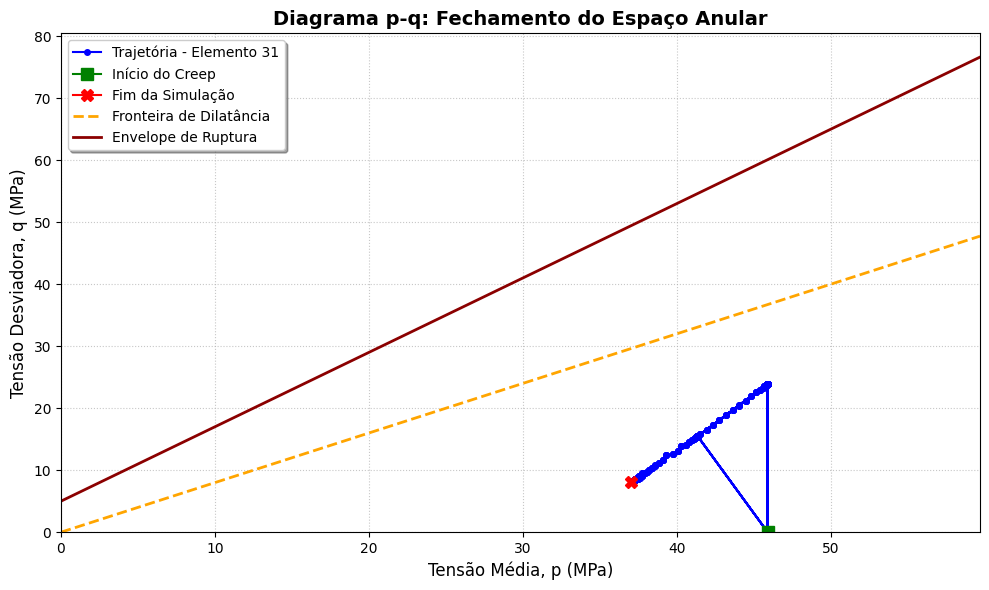

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Carregar os dados exportados
df = pd.read_csv("dados_pq_sal.csv")

# 2. Conversão de Unidades (Pascal para MPa)
# Se os seus dados no Abaqus já estiverem em MPa, comente as duas linhas abaixo.
df['p_PRESS_MPa'] = df['p_PRESS_MPa'] / 1e6
df['q_MISES_MPa'] = df['q_MISES_MPa'] / 1e6

# 3. Isolar um elemento crítico (ex: o primeiro elemento da lista, que costuma ser o da parede)
# Você pode alterar 'elemento_critico' manualmente para um número específico, ex: elemento_critico = 31
elemento_critico = df['Element_Label'].unique()[0]
# df_elem = df[df['Element_Label'] == elemento_critico].sort_values(by='Time_s')
df_elem = df_elem.iloc[1:] 

p = df_elem['p_PRESS_MPa'].values
q = df_elem['q_MISES_MPa'].values

# 4. Configuração do Gráfico
plt.figure(figsize=(10, 6))

# Plotar a Trajetória de Tensões (Stress Path)
plt.plot(p, q, marker='o', linestyle='-', color='b', markersize=4, label=f'Trajetória - Elemento {elemento_critico}')

# Destacar o ponto inicial e final da simulação
plt.plot(p[0], q[0], marker='s', color='green', markersize=8, label='Início do Creep')
plt.plot(p[-1], q[-1], marker='X', color='red', markersize=8, label='Fim da Simulação')

# # Para plotar múltiplos elementos de uma vez:
# for elem in df['Element_Label'].unique()[:5]: # Plota apenas os 5 primeiros para não poluir
#     df_elem = df[df['Element_Label'] == elem].sort_values(by='Time_s')
#     plt.plot(df_elem['p_PRESS_MPa'], df_elem['q_MISES_MPa'], marker='.', linewidth=1, label=f'Elem {elem}')

# 5. Adicionar Linhas Geomecânicas (Parâmetros Didáticos/Hipotéticos)
# Ajuste as equações abaixo conforme as propriedades reais do seu sal
p_max = max(p) * 1.3 if len(p) > 0 and max(p) > 0 else 50
p_range = np.linspace(0, p_max, 100)

# Fronteira de Dilatância (Exemplo: q = 0.8 * p)
plt.plot(p_range, 0.8 * p_range, color='orange', linestyle='--', linewidth=2, label='Fronteira de Dilatância')

# Envelope de Ruptura (Exemplo: q = 5 + 1.2 * p)
plt.plot(p_range, 5.0 + 1.2 * p_range, color='darkred', linestyle='-', linewidth=2, label='Envelope de Ruptura')

# 6. Formatação Visual
plt.title('Diagrama p-q: Fechamento do Espaço Anular', fontsize=14, fontweight='bold')
plt.xlabel('Tensão Média, p (MPa)', fontsize=12)
plt.ylabel('Tensão Desviadora, q (MPa)', fontsize=12)

# Define a origem dos eixos em zero para contexto físico
plt.xlim(left=0, right=p_max)
plt.ylim(bottom=0)

plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left', frameon=True, shadow=True)

plt.tight_layout()
plt.show()